In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

df = pd.read_csv("Social_Network_Ads.csv")

print(df.head())
print(df.shape)

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
(400, 5)


In [3]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

print("Missing values:")
print(df.isnull().sum())

X = X.fillna(X.median())

Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (300, 2)
Testing data: (100, 2)


In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [6]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 0 0
 0 1 0 0 1 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 1 0 0 0
 0 1 1 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 1 0 1 0 0 1]


In [7]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[60  4]
 [ 5 31]]


In [8]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Error Rate:", round(error_rate * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Accuracy: 91.0 %
Error Rate: 9.0 %
Precision: 0.8857
Recall: 0.8611


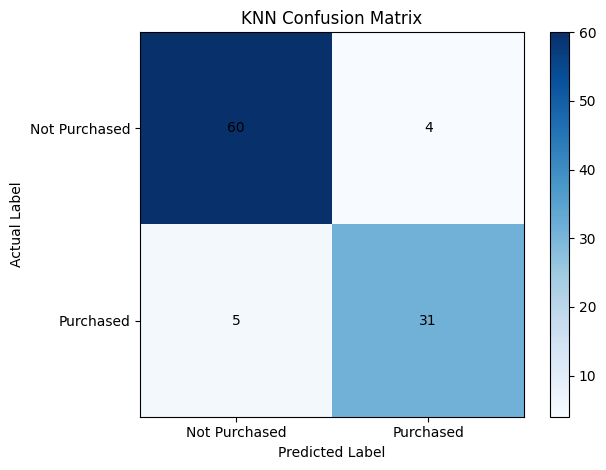

In [9]:
plt.imshow(cm, cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Not Purchased", "Purchased"])
plt.yticks([0, 1], ["Not Purchased", "Purchased"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

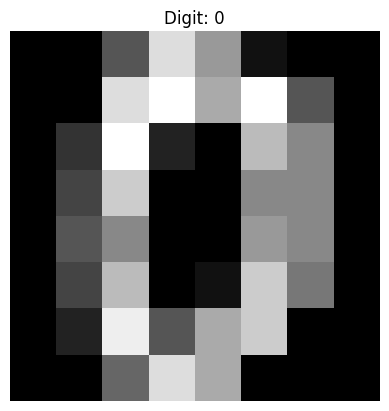

SVM Classification Accuracy: 97.77777777777777 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.97      1.00      0.98        28
           2       1.00      1.00      1.00        33
           3       0.97      0.94      0.96        34
           4       0.98      0.98      0.98        46
           5       0.96      1.00      0.98        47
           6       1.00      1.00      1.00        35
           7       0.97      0.97      0.97        34
           8       1.00      0.97      0.98        30
           9       0.95      0.93      0.94        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360

Actual Digits:    [6 9 3 7 2 1 5 2 5 2]
Predicted Digits: [6 9 3 7 2 1 5 2 5 2]


In [10]:

# Implementation of SVM for Handwritten Digit Classification

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# Step 1: Load the handwritten digits dataset
digits = load_digits()

X = digits.data
y = digits.target

# Step 2: Display a sample digit
plt.imshow(digits.images[0], cmap='gray')
plt.title(f"Digit: {y[0]}")
plt.axis('off')
plt.show()

# Step 3: Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Create and train the SVM classifier
model = SVC(kernel='linear')
model.fit(X_train, y_train)

# Step 5: Predict the digits
y_pred = model.predict(X_test)

# Step 6: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("SVM Classification Accuracy:", accuracy * 100, "%")

# Step 7: Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 8: Display actual and predicted digits
print("Actual Digits:   ", y_test[:10])
print("Predicted Digits:", y_pred[:10])
